764
764


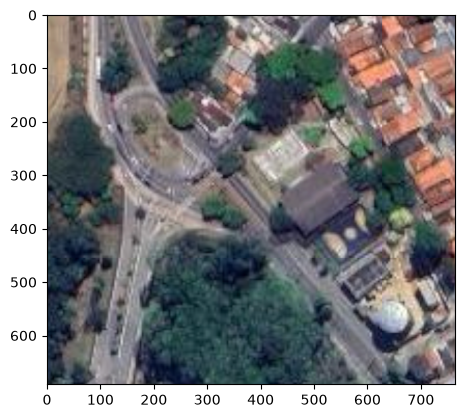

In [ ]:
# Binary classification example

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np

# load image from file
data_path = "data/"
#file_name = "foto_sp_verde.bmp"
file_name = "main_entrance_of_inpe_rgb.bmp"
img = mpimg.imread(data_path + file_name)

# display the image
plt.imshow(img)
print(len(img[0]))
print(len(img[1]))      

positive
[ 49  80  84 255]
80


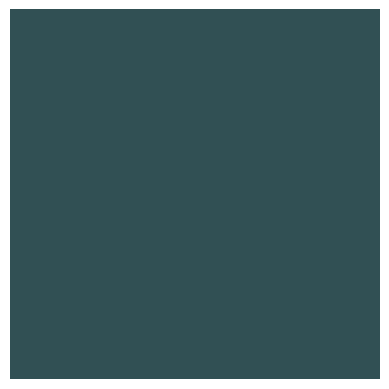

positive
[ 43 108  75 255]
108


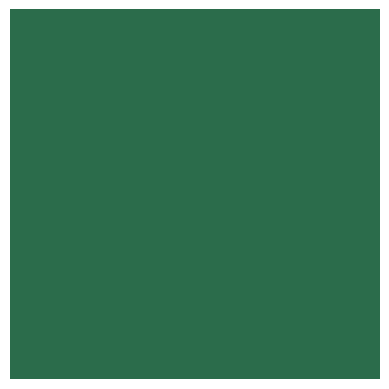

positive
[  8  20  46 255]
20


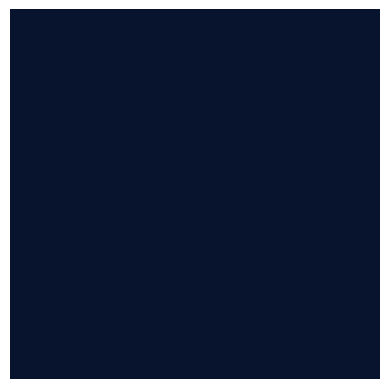

negative
[238 163 147 255]
163


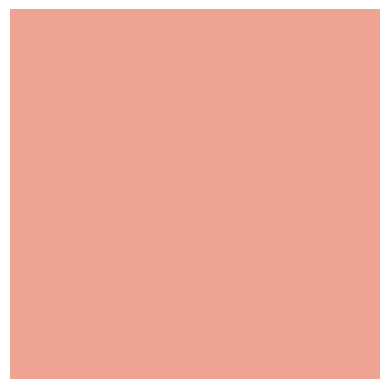

negative
[117 111 115 255]
111


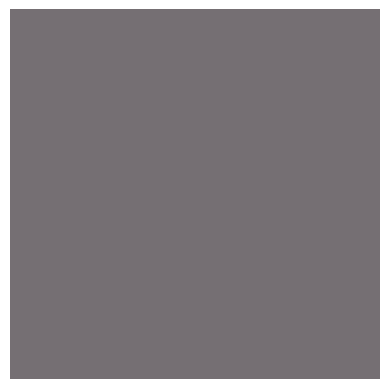

negative
[ 66  67  97 255]
67


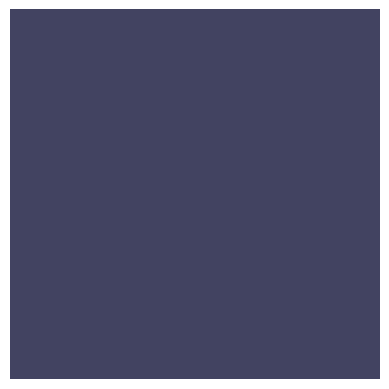

In [3]:
def logistic(red,green,blue,a,b,c,d):
    return 1/(1+np.exp(-(a*red+b*green+c*blue+d)))

#example pairs: (x,y,green probability)
""" sp verde:
examples = [(462,237,1), (240,735,1),
            (551,583,0),(400,814,0),(614,584,0)]
"""
#inpe
examples = [(570,289,1), (97,439,1),(484,345,1),
            (203,670,0),(253,160,0),(387,551,0)]


#print negative and positive examples:
for ex in examples:
    if ex[2] == 1: 
        print ("positive")
    else:
        print("negative")
    print(img[ex[0],ex[1]])
    print(img[ex[0],ex[1]][1])
    pixel = np.array([[img[ex[0],ex[1]]]], dtype=np.uint8)  
    plt.imshow(pixel)
    plt.axis('off')
    plt.show()

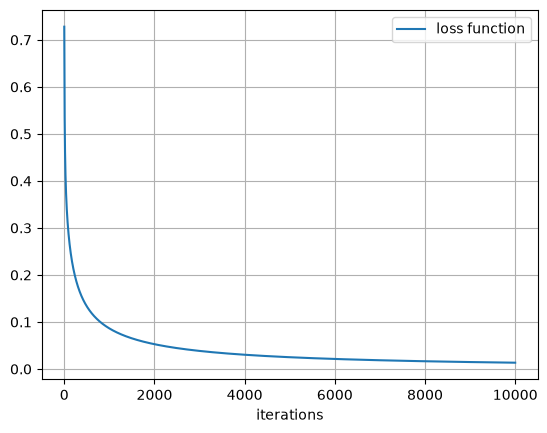

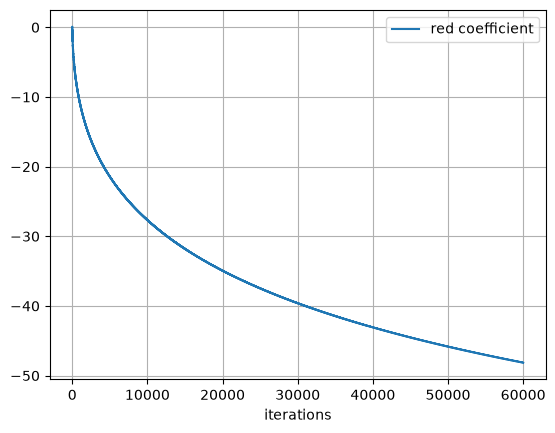

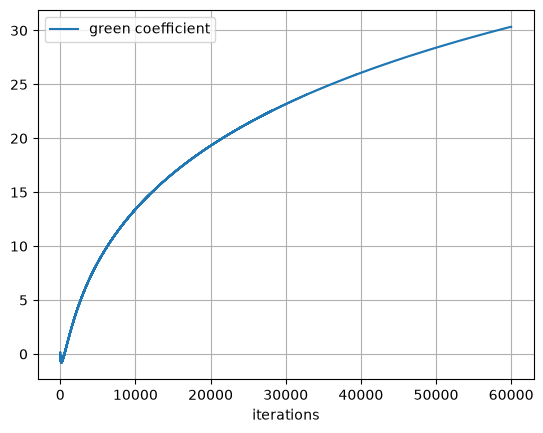

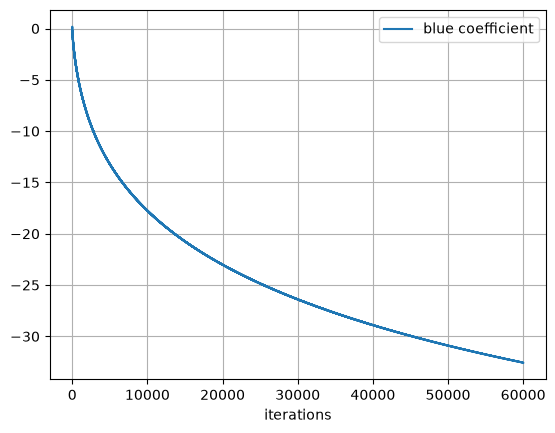

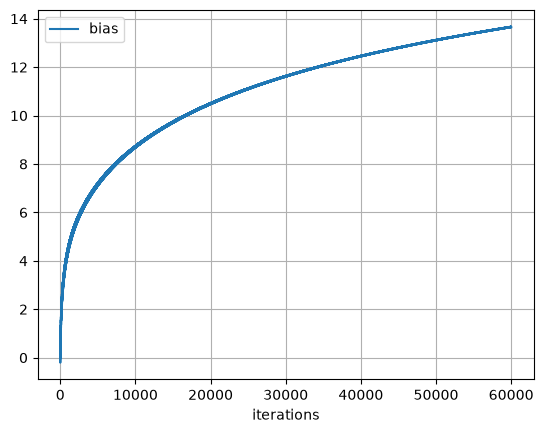

In [ ]:
# Conversão para reflectância "simulada"
def rgb_2_reflect(rgb_level):
    return (rgb_level/255)


#Treinamento do modelo de classificação:
epsilon = 1e-10
N = len(examples)
n_epochs = 10000
eta = 0.5
a = 0
a_t = [a]
b = 0
b_t = [b]
c = 0
c_t = [c]
d = 0
d_t = [d]
loss = []
for epoch in range(n_epochs):
    L = 0
    for example in examples:
        red = rgb_2_reflect(img[example[0],example[1]][0])
        green = rgb_2_reflect(img[example[0],example[1]][1])
        blue = rgb_2_reflect(img[example[0],example[1]][2])
        y_hat = logistic(red, green, blue,a,b,c,d)
        y = example[2]
        e = y - y_hat
        L = L  - y*np.log(y_hat+epsilon) - (1-y)*np.log(1-y_hat+epsilon)
        a = a + eta*e*red
        b = b + eta*e*green
        c = c + eta*e*blue
        d = d + eta*e
        a_t.append(a)
        b_t.append(b)
        c_t.append(c)
        d_t.append(d)
    loss.append(L/N)
plt.plot(loss, label = "loss function")
plt.xlabel("iterations")
plt.legend()
plt.grid()
plt.show()

plt.plot(a_t, label="red coefficient")
plt.xlabel("iterations")
plt.legend()
plt.grid()
plt.show()

plt.plot(b_t, label="green coefficient")
plt.xlabel("iterations")
plt.legend()
plt.grid()
plt.show()

plt.plot(c_t, label="blue coefficient")
plt.xlabel("iterations")
plt.legend()
plt.grid()
plt.show()


plt.plot(d_t, label="bias")
plt.xlabel("iterations")
plt.legend()
plt.grid()
plt.show()

    

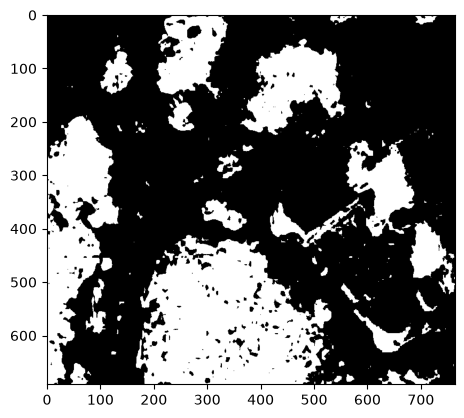

In [8]:
# Testando a classificação dos pixels com o modelo treinado:
n_rows = len(img)
n_cols = len(img[0])
classified_img = np.zeros((n_rows, n_cols, 3), dtype=np.uint8)  # n_rows x n_cols RGB
for row in range(n_rows):
    for col in range(n_cols):
        red = rgb_2_reflect(img[row,col][0])
        green = rgb_2_reflect(img[row,col][1])
        blue = rgb_2_reflect(img[row,col][2])
        x = exg(red,green,blue)
        p_veg = logistic(red,green,blue,a,b,c,d)
        if p_veg  > 0.7:
            classified_img[row,col] = [255, 255, 255]
        else:
            classified_img[row,col] = [0, 0, 0]


fig, ax = plt.subplots()
#ax.imshow(img)
ax.imshow(classified_img) #, alpha=0.5)

        